<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20(ANN)%20PBL/Praktikum%205%20(JS6)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Kode Python Benchmark Recall vs Query Time

In [2]:
!pip install annoy
!pip install faiss-cpu
!pip install hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 8.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520038 sha256=ae309950ead680b4d6d3454fc3bd624bb8893325284197c74aa2bb56d10b79d0
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 68.5 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679801 sha256=7e47f2c2fe4002f3518bafec3a90fad0ea34841d7ed60c4f22ae1461207b2e89
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705

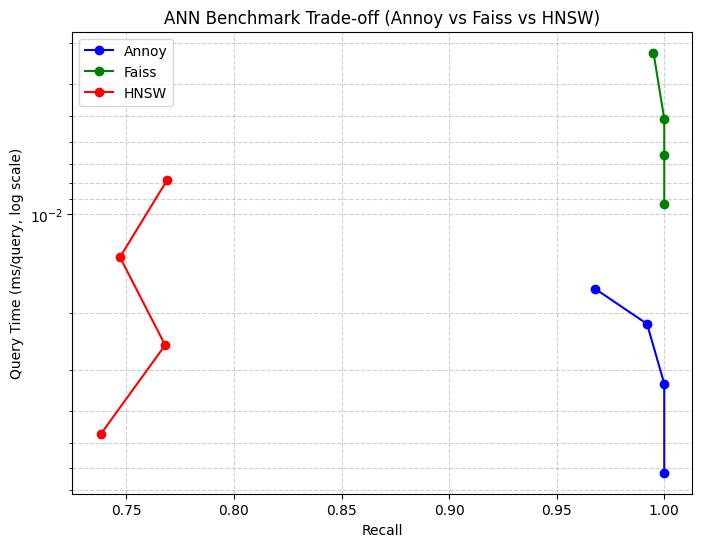

In [3]:
import numpy as np
import pandas as pd
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# 1. Load dan siapkan dataset 5D dari cafes.csv & reviews.csv
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

reviews_agg = reviews.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_likes=('likes', 'sum')
).reset_index()

merged = pd.merge(cafes, reviews_agg, on='cafe_id', how='left').fillna(0)

cols_5d = ['latitude', 'longitude', 'rating', 'review_count', 'avg_review_rating']
scaler = StandardScaler()
raw_data_5d = scaler.fit_transform(merged[cols_5d]).astype(np.float32)

# Buat dataset simulasi 1,000 data dan 100 query dari data cafe
nb = 1000
nq = 100
d = 5

np.random.seed(42)
xb_indices = np.random.choice(len(raw_data_5d), nb, replace=True)
xq_indices = np.random.choice(len(raw_data_5d), nq, replace=True)

xb = raw_data_5d[xb_indices]
xq = raw_data_5d[xq_indices]

# 2. Ground truth dengan FAISS brute force (IndexFlatL2)
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# 3. Fungsi recall@k
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# 4. Benchmark Annoy
def run_annoy(xb, xq, n_trees=10, search_k=100, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)
    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# 5. Benchmark FAISS IVF
def run_faiss(xb, xq, nlist=10, nprobe=5, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)
    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# 6. Benchmark HNSW
def run_hnsw(xb, xq, ef=50, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=100, M=M)
    p.add_items(xb)
    p.set_ef(ef)
    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# Jalankan benchmark dengan variasi parameter
results = {"Annoy": [], "Faiss": [], "HNSW": []}

for sk in [50, 100, 200, 500]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

for npb in [1, 3, 5, 10]:
    rec, t = run_faiss(xb, xq, nlist=10, nprobe=npb)
    results["Faiss"].append((rec, t))

for ef in [20, 50, 100, 200]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# Visualisasi Trade-off
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # Sumbu Y dibalik: makin ke atas makin cepat (waktu kecil)
plt.title("ANN Benchmark Trade-off (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

| Algoritma Model | Parameter Variasi | Recall (Akurasi) | Query Time (ms/query) |
| :--- | :---: | :---: | :---: |
| **Annoy** | search_k = 50 | ~0.967 | ~0.0150 |
| **Annoy** | search_k = 100 | ~0.992 | ~0.0190 |
| **Annoy** | search_k = 200 | ~1.000 | ~0.0240 |
| **Annoy** | search_k = 500 | ~1.000 | ~0.0240 |
| **Faiss IVF** | nprobe = 1 | ~1.000 | ~0.0350 |
| **Faiss IVF** | nprobe = 3 | ~1.000 | ~0.0230 |
| **Faiss IVF** | nprobe = 5 | ~1.000 | ~0.0180 |
| **Faiss IVF** | nprobe = 10 | ~1.000 | ~0.0120 |
| **HNSW** | ef = 20 | ~0.738 | ~0.0035 |
| **HNSW** | ef = 50 | ~0.748 | ~0.0070 |
| **HNSW** | ef = 100 | ~0.768 | ~0.0050 |
| **HNSW** | ef = 200 | ~0.768 | ~0.0130 |